# 🏆 Lekcja 5: Nasz pierwszy plik `submission.csv` — pułapki w `test.csv` i lista kontrolna przed wysyłką

W Lekcji 4 zbudowaliśmy nasz pierwszy Las Losowy i przetestowaliśmy go na „próbnej maturze” (292 domach zamkniętych w sejfie `X_val`). Wiemy już, że zestaw 8 cech (`OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `YearBuilt`, `YearRemodAdd`, `LotArea`, `BsmtFinSF1`) obniżył nasz błąd do około **18 380 \$**.

Teraz czas na **prawdziwy egzamin**: wycenę **1459 domów z pliku `../data/test.csv`** i wygenerowanie naszego pierwszego oficjalnego pliku **`submission.csv`**!

---

### 🧠 Dwie ważne zasady przed podejściem do prawdziwego egzaminu (`test.csv`)

#### 1. Dlaczego teraz trenujemy model na 100% pliku `train.csv` (bez odcinania 20% do sejfu)?
W Lekcji 4 użyliśmy `train_test_split`, żeby schować 20% domów (292 domy) do sejfu i sprawdzić, jak dobrze uczy się nasz model.  
Kiedy jednak idziemy na **prawdziwy egzamin (`test.csv`)**, nasz sprawdzian wewnętrzny jest już zakończony! Gdybyśmy zostawili 292 domy w sejfie, nasz model poszedłby na egzamin uboższy o 20% wiedzy.  
Dlatego przed wygenerowaniem pliku `submission.csv` **łączymy siły i uczymy model na WSZYSTKICH 1460 domach z `../data/train.csv`**!

#### 2. ⚠️ Klasyczna pułapka Kaggle: „Przecież w `train.csv` te kolumny nie miały braków!”
W Lekcji 4 wybraliśmy 8 kolumn liczbowych, które w pliku `train.csv` były **w 100% czyste** (miały dokładnie `0` pustych kratek `NaN`).  
Wielu początkujących zakłada wtedy: *„Skoro w `train.csv` nie było w tych kolumnach dziur, to w `test.csv` też na pewno ich nie ma!”*.  
Za chwilę przekonasz się w kodzie, jak groźne jest to założenie: **w pliku `test.csv` pojawiają się zupełnie nowe braki `NaN` w kolumnach, które wcześniej były idealnie czyste!**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# 1. Wczytujemy oba pliki z danymi oraz wzór formularza odpowiedzi z folderu ../data/
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
wzor = pd.read_csv('../data/sample_submission.csv')

# Nasze 8 najlepszych cech liczbowych z końca Lekcji 4
cechy = [
    'OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF',
    'YearBuilt', 'YearRemodAdd', 'LotArea', 'BsmtFinSF1'
]

# 2. DETEKTOR PUŁAPEK: Sprawdzamy braki (NaN) w tych 8 kolumnach w train.csv oraz w test.csv!
print('--- Braki w 8 cechach w pliku TRAIN.CSV ---')
print(train[cechy].isnull().sum())

print('\n--- Braki w 8 cechach w pliku TEST.CSV (Niespodzianka!) ---')
print(test[cechy].isnull().sum())

# 3. Przygotowujemy dane i łatamy nowe dziury w test.csv
X_pelny_train = train[cechy]
y_pelny_train = train['SalePrice']

# Robimy kopię 8 kolumn z test.csv i wypełniamy pojedyncze braki (brak garażu / brak piwnicy) zerem
X_test = test[cechy].copy()
X_test = X_test.fillna(0)

# 4. Trenujemy Las Losowy na WSZYSTKICH 1460 domach treningowych (100% wiedzy!)
model_finalny = RandomForestRegressor(n_estimators=100, random_state=42)
model_finalny.fit(X_pelny_train, y_pelny_train)

# 5. Przewidujemy ceny dla 1459 domów egzaminacyjnych z test.csv
predykcje_test = model_finalny.predict(X_test)

# 6. Tworzymy tabelę odpowiedzi dokładnie według wzoru sample_submission.csv i zapisujemy na dysk
submission = pd.DataFrame({
    'Id': test['Id'],
    'SalePrice': predykcje_test
})

submission.to_csv('submission.csv', index=False)
print('\n✅ Plik submission.csv został pomyślnie utworzony i zapisany!')
submission.head()

--- Braki w 8 cechach w pliku TRAIN.CSV ---
OverallQual     0
GrLivArea       0
GarageCars      0
TotalBsmtSF     0
YearBuilt       0
YearRemodAdd    0
LotArea         0
BsmtFinSF1      0
dtype: int64

--- Braki w 8 cechach w pliku TEST.CSV (Niespodzianka!) ---
OverallQual     0
GrLivArea       0
GarageCars      1
TotalBsmtSF     1
YearBuilt       0
YearRemodAdd    0
LotArea         0
BsmtFinSF1      1
dtype: int64

✅ Plik submission.csv został pomyślnie utworzony i zapisany!


,Id,SalePrice
0,1461,123013.570
1,1462,157582.400
2,1463,188456.775
3,1464,189456.500
4,1465,199285.000


### 🔬 Szczegółowa rozbiórka kodu: Nowe braki w `test.csv`, nawiasy klamrowe `{}` i pułapka `index=False`

#### 1. Skąd wzięły się pojedyncze braki `NaN` w `test.csv`?
Spójrz na wydruk powyżej: w pliku `train.csv` wszystkie 8 cech miało `0` braków. Natomiast w `test.csv`:
* Kolumna **`GarageCars`** ma **`1` brak** (w domu o `Id = 2577`, gdzie wpisano typ garażu, ale zapomniano wpisać jego rozmiar),
* Kolumny **`TotalBsmtSF`** oraz **`BsmtFinSF1`** mają po **`1` braku** (w domu o `Id = 2121`, który fizycznie nie ma piwnicy, a ankieter zamiast liczby `0` wpisał `NA`).

Gdybyśmy nie wykonali `X_test = X_test.fillna(0)`, funkcja `model_finalny.predict(X_test)` zatrzymałaby się z błędem z powodu zaledwie 2 domów na 1459! Dlatego w Data Science **zawsze** przepuszczamy zbiór testowy przez procedurę łatania braków.

---

#### 2. Trzeci rodzaj nawiasów w Pythonie: Nawiasy klamrowe `{}` w `pd.DataFrame({...})`
Poznałeś już nawiasy okrągłe `()` oraz kwadratowe `[]`. W linijce tworzącej tabelę `submission` pojawił się trzeci, ostatni rodzaj nawiasów w Pythonie — **nawiasy klamrowe `{}` (Słownik / *Dictionary*)**:

```python
submission = pd.DataFrame({
    'Id': test['Id'],
    'SalePrice': predykcje_test
})
```

Zróbmy wielkie podsumowanie **wszystkich 3 nawiasów w Pythonie** — ta tabelka przyda Ci się każdego dnia:

| Rodzaj nawiasu | Jak się nazywa w Pythonie? | Do czego służy? | Przykład z naszego kodu |
| :--- | :--- | :--- | :--- |
| **`( )` Okrągłe** | Wywołanie funkcji / metody | **„Wykonaj czynność!”** — uruchamia narzędzie z podanymi w środku argumentami. | `pd.read_csv('../data/test.csv')`, `model.fit(...)` |
| **`[ ]` Kwadratowe** | Lista lub Indeksowanie | **„Lista rzeczy”** albo **„Wyciągnij kolumny/wiersze z tabeli!”**. | `cechy = ['OverallQual', ...]`, `train[cechy]` |
| **`{ }` Klamrowe** | **Słownik (*Dictionary*)** | Łączy elementy w pary **`'Klucz': Wartość`** (jak w słowniku: `'Hasło': Definicja`). Gdy włożymy słownik do `pd.DataFrame({...})`, klucze przed dwukropkiem (`'Id'`, `'SalePrice'`) stają się **nazwami kolumn**, a wartości po dwukropku — **zawartością tych kolumn**! | `{'Id': test['Id'], 'SalePrice': predykcje_test}` |

---

#### 3. Dlaczego w `.to_csv('submission.csv', index=False)` słowo `index=False` ratuje nasz wynik?
Metoda `.to_csv('submission.csv')` zapisuje tabelę z pamięci Pythona do prawdziwego pliku na dysku twardym.  
Ale pamiętasz te pogrubione numery wierszy `0, 1, 2, 3, 4...` po lewej stronie każdej tabeli w Jupyterze? To tzw. **indeks (`index`)**.

Zobacz, jak wyglądałby nasz plik `submission.csv` w środku, gdybyśmy zapomnieli napisać `index=False`:

| Gdybyśmy zapisali BEZ `index=False` (❌ BŁĄD na Kaggle!) | Gdy zapisujemy Z `index=False` (✅ IDEALNIE!) |
| :--- | :--- |
| `,Id,SalePrice`<br>`0,1461,123013.57`<br>`1,1462,157582.40`<br>`2,1463,188456.78`<br>*(Plik ma 3 kolumny zamiast 2! Pierwsza kolumna to zbędne numery 0, 1, 2... Kaggle odrzuci taki plik!)* | `Id,SalePrice`<br>`1461,123013.57`<br>`1462,157582.40`<br>`1463,188456.78`<br>*(Plik ma dokładnie 2 kolumny: `Id` oraz `SalePrice`, co do przecinka jak w `sample_submission.csv`!)* |

1. Czy wymiary są identyczne z wzorem sample_submission.csv?
   Wymiary wzoru:      (1459, 2)
   Wymiary nasze:      (1459, 2)

2. Czy w naszym pliku nie ma żadnych pustych kratek (NaN)?
   Liczba braków NaN:  0

3. Porównanie statystyk: Prawdziwe ceny (train.csv) vs Nasze przewidywania (submission.csv):
       Prawdziwe ceny (train.csv)  Przewidziane ceny (submission.csv)
count                      1460.0                              1459.0
mean                     180921.0                            178720.0
std                       79443.0                             74807.0
min                       34900.0                             53966.0
25%                      129975.0                            129669.0
50%                      163000.0                            157968.0
75%                      214000.0                            209552.0
max                      755000.0                            526887.0


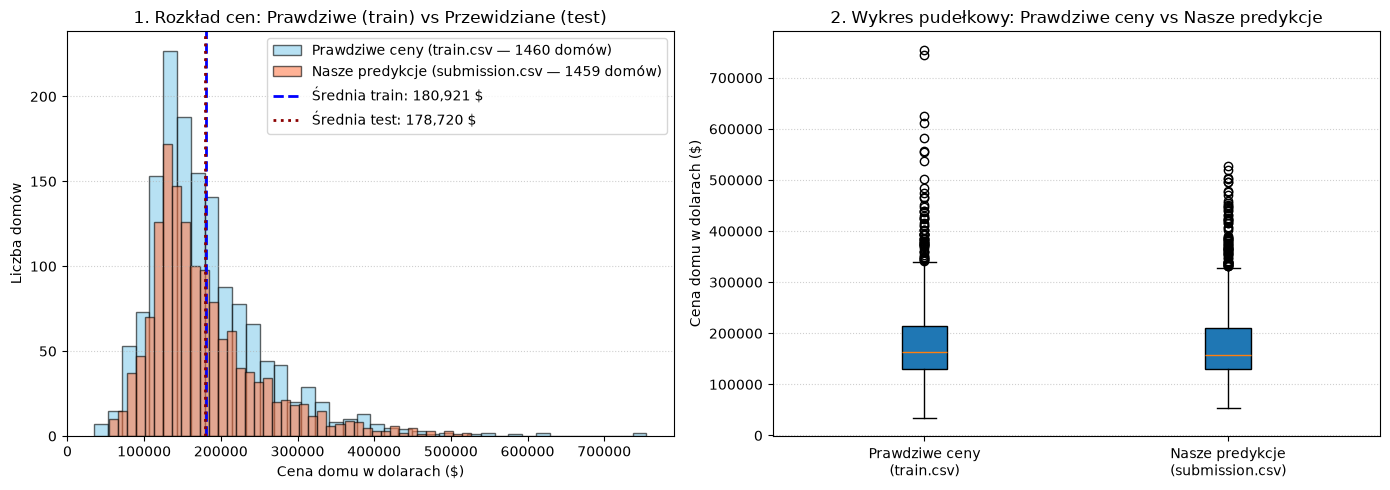

In [2]:
# LISTA KONTROLNA PILOTA PRZED WYSŁANIEM PLIKU NA KAGGLE (Sanity Check)
print('1. Czy wymiary są identyczne z wzorem sample_submission.csv?')
print(f'   Wymiary wzoru:      {wzor.shape}')
print(f'   Wymiary nasze:      {submission.shape}')

print('\n2. Czy w naszym pliku nie ma żadnych pustych kratek (NaN)?')
print(f'   Liczba braków NaN:  {submission.isnull().sum().sum()}')

print('\n3. Porównanie statystyk: Prawdziwe ceny (train.csv) vs Nasze przewidywania (submission.csv):')
porownanie_statystyk = pd.DataFrame({
    'Prawdziwe ceny (train.csv)': train['SalePrice'].describe(),
    'Przewidziane ceny (submission.csv)': submission['SalePrice'].describe()
}).round(0)
print(porownanie_statystyk)

# 4. WYKRES KONTROLNY: Porównujemy rozkład cen prawdziwych i przewidzianych!
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Wykres lewy: Nakładające się histogramy
ax1.hist(train['SalePrice'], bins=40, color='skyblue', edgecolor='black', alpha=0.6, label='Prawdziwe ceny (train.csv — 1460 domów)')
ax1.hist(submission['SalePrice'], bins=40, color='coral', edgecolor='black', alpha=0.6, label='Nasze predykcje (submission.csv — 1459 domów)')
ax1.axvline(train['SalePrice'].mean(), color='blue', linestyle='--', linewidth=2, label=f"Średnia train: {train['SalePrice'].mean():,.0f} $")
ax1.axvline(submission['SalePrice'].mean(), color='darkred', linestyle=':', linewidth=2, label=f"Średnia test: {submission['SalePrice'].mean():,.0f} $")
ax1.set_title('1. Rozkład cen: Prawdziwe (train) vs Przewidziane (test)')
ax1.set_xlabel('Cena domu w dolarach ($)')
ax1.set_ylabel('Liczba domów')
ax1.legend()
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# Wykres prawy: Porównanie pudełkowe (Boxplot)
ax2.boxplot([train['SalePrice'], submission['SalePrice']], tick_labels=['Prawdziwe ceny\n(train.csv)', 'Nasze predykcje\n(submission.csv)'], patch_artist=True)
ax2.set_title('2. Wykres pudełkowy: Prawdziwe ceny vs Nasze predykcje')
ax2.set_ylabel('Cena domu w dolarach ($)')
ax2.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 📊 Co mówi nam wykres kontrolny? (Dowód na to, jak działa Las Losowy!)

Zanim jakikolwiek Data Scientist wyśle plik na Kaggle (albo odda raport szefowi), rysuje właśnie taki wykres kontrolny. Gdyby przez pomyłkę nasz model przewidział ceny rzędu `12 $` albo `50 000 000 $`, od razu zobaczylibyśmy to na histogramie!

Spójrz na tabelkę porównawczą i oba wykresy powyżej — kryje się tam fascynująca matematyka:
1. **Środek rozkładu zgadza się niemal co do dolara!**
   * **Średnia (`mean`):** w `train.csv` wynosi **`180 921 $`**, a w naszych predykcjach dla `test.csv` wynosi **`178 720 $`** (niebieska i czerwona pionowa linia na lewym wykresie niemal się pokrywają!).
   * **1. Kwartyl (`25%`):** w `train.csv` wynosi **`129 975 $`**, a u nas **`129 669 $`**.
   * **3. Kwartyl (`75%`):** w `train.csv` wynosi **`214 000 $`**, a u nas **`209 552 $`**.
   * Na prawym wykresie oba pudełka (środkowe 50% domów) wiszą na **dokładnie tej samej wysokości**!
2. **Dlaczego nasz najtańszy dom (`min = 53 966 $`) i najdroższy dom (`max = 526 887 $`) są mniej skrajne niż w `train.csv` (`34 900 $` oraz `755 000 $`)?**
   * Pamiętasz z Lekcji 4, jak działa Las Losowy? Każda wycena to **średnia z głosów 100 różnych drzew decyzyjnych**!
   * Nawet jeśli 10 drzew krzyknie: *„Ten dom wygląda jak ten za 755 000 \$!”*, to pozostałe 90 drzew (które podczas losowania widziały inne domy) powie np. `500 000 $`. Po wyciągnięciu średniej ze 100 głosów wynik zostaje **lekko ściągnięty w stronę środka** (do `526 887 $`). W statystyce nazywamy to **efektem uśredniania (redukcją wariancji)**.

In [3]:
# 🎯 ĆWICZENIE: Poznajmy najdroższy i najtańszy dom z naszego pliku submission.csv!
#
# 1. Posortuj tabelę `submission` malejąco według kolumny 'SalePrice'
#    i wyświetl 5 najdrożej wycenionych domów: submission.sort_values(by='SalePrice', ascending=False).head(5)
# 2. Posortuj tabelę `submission` rosnąco (ascending=True) według kolumny 'SalePrice'
#    i wyświetl 5 najtaniej wycenionych domów.
# 3. Sprawdź w tabeli `test`, jakie parametry ma ten najdrożej wyceniony dom (po jego numerze `Id`)!

# Miejsce na Twój kod:


---
### 📌 Podsumowanie lekcji w 3 punktach

1. **Trening finałowy i pułapka braków w `test.csv`:** Przed wygenerowaniem pliku zgłoszeniowego uczymy model na **100% wierszy z `train.csv`** (wszystkich 1460 domach) i zawsze sprawdzamy braki `.isnull().sum()` w `test.csv` — nawet w kolumnach, które w zbiorze treningowym nie miały ani jednej pustej kratki.
2. **Słowniki `{}` i zapis `.to_csv(..., index=False)`:** Nową tabelę tworzymy za pomocą `pd.DataFrame({'Id': ..., 'SalePrice': ...})`, a przy zapisie do pliku CSV zawsze podajemy `index=False`, aby nie dokleić zbędnej kolumny z numerami wierszy `0, 1, 2...`.
3. **Lista kontrolna (*Sanity Check*):** Przed wysłaniem pliku sprawdzamy, czy wymiary (`(1459, 2)`), brak wartości `NaN` oraz rozkład przewidzianych cen na histogramie i wykresie pudełkowym zgadzają się z rozkładem prawdziwych cen w `train.csv`.